# 4. E fora do Brasil?

O texto diz que juro abaixo da inflação "não é excepcional", cita Argentina, Turquia, Estados Unidos e Europa, e
refaz para os Estados Unidos a comparação que fez para o Brasil: bolsa e ouro contra o dinheiro em circulação.

Este notebook separa as duas coisas. Primeiro, o juro real de 17 países, pela régua usual. Depois, os números
americanos do texto.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from juro_negativo import analise, estilo
from juro_negativo.caminhos import TRATADOS
from juro_negativo.estilo import br, pct
from juro_negativo.exportar_site import PAISES_DO_MAPA
from juro_negativo.fontes import afirmacoes

estilo.aplicar()

paises = pd.read_parquet(TRATADOS / "paises.parquet")
eua = pd.read_parquet(TRATADOS / "eua.parquet")
niveis_eua = analise.niveis_dos_eua(eua)
juro_real = paises.pivot(index="data", columns="pais", values="juro_real_aa")[PAISES_DO_MAPA]

## O juro real de 17 países

Para cada país e cada mês: o juro básico definido pelo banco central, descontada a inflação ao consumidor dos 12
meses anteriores. Os dados são do BIS, o banco dos bancos centrais.

O mapa mostra a média de cada ano. A faixa vermelha de 2009 a 2021, nos países ricos, é o juro negativo de que o
texto fala. Ela existe. A linha do Brasil é quase toda azul.

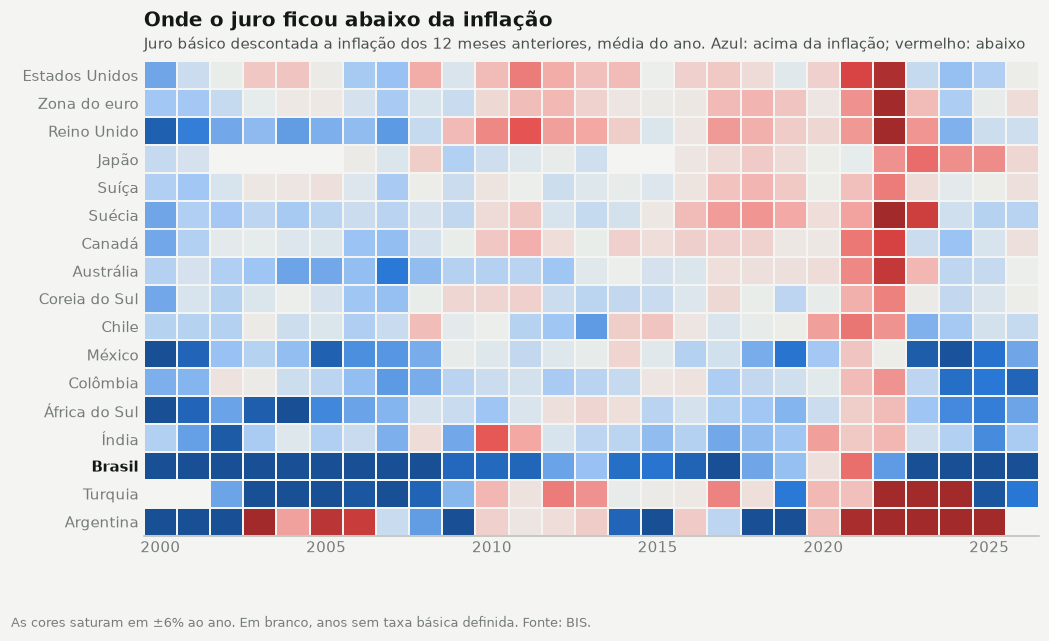

In [2]:
anual = juro_real.groupby(juro_real.index.year).mean().loc[2000:].T

fig, ax = plt.subplots(figsize=(10.5, 5.6))
ax.pcolormesh(
    anual.columns,
    np.arange(len(anual)),
    np.ma.masked_invalid(anual.to_numpy()),
    cmap=estilo.DIVERGENTE,
    vmin=-0.06,
    vmax=0.06,
    edgecolors=estilo.SUPERFICIE,
    linewidth=1,
)
ax.set_yticks(np.arange(len(anual)), anual.index)
ax.invert_yaxis()
ax.grid(False)
ax.tick_params(axis="both", length=0)
for rotulo in ax.get_yticklabels():
    if rotulo.get_text() == "Brasil":
        rotulo.set_fontweight("bold")
        rotulo.set_color(estilo.TINTA)
estilo.titulo(
    ax,
    "Onde o juro ficou abaixo da inflação",
    "Juro básico descontada a inflação dos 12 meses anteriores, média do ano. Azul: acima da inflação; vermelho: abaixo",
)
estilo.fonte(fig, "As cores saturam em ±6% ao ano. Em branco, anos sem taxa básica definida. Fonte: BIS.")
plt.show()

In [3]:
PERIODOS = {
    "2000 a 2008": ("2000-01", "2008-12"),
    "2009 a 2021": ("2009-01", "2021-12"),
    "2023 em diante": ("2023-01", None),
}
negativos = pd.DataFrame(
    {periodo: juro_real.loc[inicio:fim].apply(analise.fracao_negativa) for periodo, (inicio, fim) in PERIODOS.items()}
)
medias = pd.DataFrame(
    {f"média {periodo}": juro_real.loc[inicio:fim].mean() for periodo, (inicio, fim) in PERIODOS.items()}
)
print("Fração dos meses com juro abaixo da inflação, e juro real médio:")
pd.concat([negativos.map(lambda v: pct(v)), medias.map(lambda v: pct(v, 1, sinal=True))], axis=1)

Fração dos meses com juro abaixo da inflação, e juro real médio:


,2000 a 2008,2009 a 2021,2023 em diante,média 2000 a 2008,média 2009 a 2021,média 2023 em diante
pais,,,,,,
Estados Unidos,43%,83%,19%,"+0,4%","−1,2%","+1,2%"
Zona do euro,22%,83%,43%,"+0,8%","−0,9%","−0,0%"
Reino Unido,3%,89%,20%,"+2,9%","−1,6%","+0,4%"
Japão,45%,50%,100%,"−0,0%","+0,1%","−2,5%"
Suíça,43%,50%,55%,"+0,6%","−0,3%","−0,2%"
Suécia,1%,69%,34%,"+1,5%","−0,7%","−0,5%"
Canadá,15%,87%,23%,"+1,1%","−0,8%","+0,9%"
Austrália,6%,40%,33%,"+2,2%","+0,2%","+0,2%"
Coreia do Sul,17%,44%,23%,"+1,1%","+0,1%","+0,4%"


Entre 2009 e 2021, o juro básico ficou abaixo da inflação em 83% dos meses nos Estados Unidos, 83% na zona do
euro, 89% no Reino Unido e 87% no Canadá. No Brasil, em 12%.

Depois de 2022 o quadro mudou. Com a inflação de volta, os bancos centrais subiram os juros, e desde 2023 o juro
americano ficou abaixo da inflação em só 19% dos meses. A exceção é o Japão, onde continua abaixo em todos.

**Nesse ponto o texto tem razão**, e sem precisar trocar de régua: juro real negativo foi a regra nos países
ricos por mais de uma década. O que não se sustenta é estender isso ao Brasil.

## Abaixo de zero mesmo

O texto vai além: diz que o juro negativo "não é excepcional - até em termos nominais (e não apenas reais)". Juro
nominal negativo é a taxa abaixo de zero antes de descontar a inflação: o banco paga para deixar dinheiro no
banco central.

Isso foi bem mais raro. Dos 17 países comparados, só 3 tiveram a taxa básica abaixo de zero: a Suíça (93 meses,
até −0,75%), o Japão (90 meses, −0,10%) e a Suécia (59 meses, até −0,50%). Na zona do euro, a taxa que ficou
negativa foi a que o banco central paga pelos depósitos dos bancos, de junho de 2014 a julho de 2022 (até
−0,50%); a taxa básica, que é a que o BIS registra, parou em zero. Estados Unidos, Reino Unido, Canadá e
Austrália chegaram perto de zero e não passaram.

Existiu e durou anos, mas em poucos lugares. Nesse trecho o texto vai além dos dados.

In [4]:
nominais = analise.meses_de_juro_nominal_negativo(paises[paises["pais"].isin(PAISES_DO_MAPA)])
print(f"Países com juro básico abaixo de zero em algum mês: {len(nominais)} de {len(PAISES_DO_MAPA)}")
minimos = paises[paises["data"] >= "2009-01-01"].groupby("pais")["juro_aa"].min()
print(
    "Menor juro básico desde 2009:",
    ", ".join(
        f"{pais} {pct(minimos[pais], 2)}"
        for pais in ["Estados Unidos", "Reino Unido", "Canadá", "Austrália", "Zona do euro"]
    ),
)
pd.DataFrame(
    {
        "meses": nominais["meses"],
        "de": nominais["de"].dt.strftime("%m/%Y"),
        "até": nominais["ate"].dt.strftime("%m/%Y"),
        "taxa mínima": nominais["minimo"].map(lambda v: pct(v, 2)),
    }
).set_axis(nominais["pais"]).sort_values("meses", ascending=False)

Países com juro básico abaixo de zero em algum mês: 3 de 17
Menor juro básico desde 2009: Estados Unidos 0,12%, Reino Unido 0,10%, Canadá 0,25%, Austrália 0,10%, Zona do euro 0,00%


,meses,de,até,taxa mínima
pais,,,,
Suíça,93,12/2014,08/2022,"−0,75%"
Japão,90,09/2016,02/2024,"−0,10%"
Suécia,59,02/2015,12/2019,"−0,50%"


## Os números dos Estados Unidos

O texto compara o S&P 500 e o ouro com o M1 americano (a série `M1SL`) em três períodos, e conclui que depois de
2008 "mercados renderam menos que inflação". A tabela refaz os três, acrescentando o que o texto não mostra: o
S&P 500 com dividendos, o M2, os preços ao consumidor (CPI) e as duas medidas mais estreitas de dinheiro, que são
o papel-moeda em circulação e a base monetária (o papel-moeda mais as reservas dos bancos no Federal Reserve).

In [5]:
NOMES = {
    "sp500": "S&P 500 (preço)",
    "sp500_total": "S&P 500 com dividendos",
    "ouro": "Ouro",
    "m1": "M1",
    "m2": "M2",
    "base_monetaria": "Base monetária",
    "papel_moeda": "Papel-moeda em circulação",
    "cpi": "Preços (CPI)",
}
PERIODOS_DO_TEXTO = [("1998-01", "2008-01"), ("2008-01", "2018-01"), ("2018-01", "2022-01")]

refeito = pd.DataFrame(
    {
        f"jan/{inicio[:4]} a jan/{fim[:4]}": analise.variacao(niveis_eua, inicio, fim)[list(NOMES)]
        for inicio, fim in PERIODOS_DO_TEXTO
    }
).rename(NOMES)
citado = afirmacoes.ler().query("pais == 'Estados Unidos'")
print("No texto:")
print(citado.pivot(index="serie", columns="grupo", values="variacao_citada").map(lambda v: pct(v, 1)).to_string())
refeito.map(lambda v: pct(v, 1))

No texto:
grupo 1998 a 2008 2008 a 2018 2018 a 2022
serie                                    
m1          28,3%      165,4%      415,5%
ouro       232,6%       53,0%       18,5%
sp500       51,7%      126,2%       40,5%


,jan/1998 a jan/2008,jan/2008 a jan/2018,jan/2018 a jan/2022
S&P 500 (preço),"53,7%","80,1%","75,5%"
S&P 500 com dividendos,"79,5%","122,6%","88,2%"
Ouro,"177,9%","57,4%","41,6%"
M1,"28,1%","164,8%","461,6%"
M2,"85,5%","85,6%","54,8%"
Base monetária,"69,8%","360,0%","66,5%"
Papel-moeda em circulação,"73,0%","95,4%","38,5%"
Preços (CPI),"30,2%","17,4%","13,1%"


## O salto de 415% do M1 é uma mudança de definição

O número que sustenta a conclusão sobre os Estados Unidos é o crescimento do M1 de 2018 a 2022: 415,5% no texto,
461,6% na série oficial. Nenhum dos dois é emissão de moeda.

Em maio de 2020, o Federal Reserve mudou a definição do M1. As contas de poupança, que antes entravam só no M2,
passaram a contar também no M1, porque deixou de existir o limite de saques que as distinguia das
contas-correntes. De abril para maio de 2020, o M1 foi de US$ 4,9 trilhões para US$ 16,3 trilhões. O dinheiro já
existia; mudou de coluna.

O M2, que já incluía a poupança, mostra o que de fato aconteceu: cresceu 54,8% de 2018 a 2022. O papel-moeda em
circulação, que é o dinheiro no sentido mais literal, cresceu 38,5%, e a base monetária, 66,5%. Foi muito (a
resposta à pandemia), mas o S&P 500 rendeu mais que qualquer um dos três no período: 75,5% no preço e 88,2% com
dividendos.

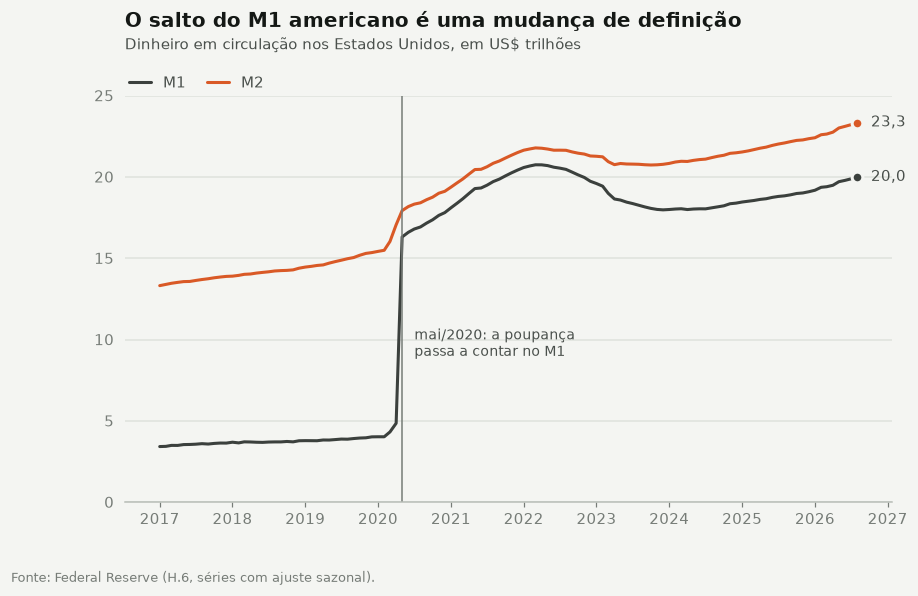

M1: US$ 4,9 tri em abr/2020 → US$ 16,3 tri em mai/2020
M2: US$ 17,1 tri → US$ 17,9 tri


In [6]:
dinheiro = eua.set_index("data").loc["2017-01-01":, ["m1", "m2"]] / 1000

fig, ax = plt.subplots()
ax.plot(dinheiro["m1"], color=estilo.GRAFITE, label="M1")
ax.plot(dinheiro["m2"], color=estilo.LARANJA, label="M2")
ax.axvline(pd.Timestamp("2020-05-01"), color=estilo.TINTA_SUAVE, lw=1)
ax.annotate(
    "mai/2020: a poupança\npassa a contar no M1",
    (pd.Timestamp("2020-05-01"), 9),
    xytext=(8, 0),
    textcoords="offset points",
    fontsize=9,
    color=estilo.TINTA_SECUNDARIA,
)
estilo.titulo(
    ax,
    "O salto do M1 americano é uma mudança de definição",
    "Dinheiro em circulação nos Estados Unidos, em US$ trilhões",
    legenda=True,
)
ax.set_ylim(0, 25)
estilo.rotular_fins(ax, lambda v: br(v, 1))
estilo.fonte(fig, "Fonte: Federal Reserve (H.6, séries com ajuste sazonal).")
plt.show()

print(
    f"M1: US$ {br(dinheiro.loc['2020-04-01', 'm1'], 1)} tri em abr/2020 → US$ {br(dinheiro.loc['2020-05-01', 'm1'], 1)} tri em mai/2020"
)
print(f"M2: US$ {br(dinheiro.loc['2020-04-01', 'm2'], 1)} tri → US$ {br(dinheiro.loc['2020-05-01', 'm2'], 1)} tri")

## E com as outras medidas de dinheiro?

Trocando o M1 pelo M2, e contando os dividendos, a conclusão do texto para os Estados Unidos não se mantém:

- **1998 a 2008**: o S&P 500 com dividendos rendeu 79,5% e o M2 cresceu 85,5%. Empate, com leve desvantagem
  para a bolsa (a década começa perto do pico da bolha da internet e termina às vésperas da crise).
- **2008 a 2018**: 122,6% contra 85,6%. A bolsa ganhou.
- **2018 a 2022**: 88,2% contra 54,8%. A bolsa ganhou.

Com a **base monetária**, que é a definição que o texto diz usar, o resultado de 2008 a 2018 é o oposto. Ela
multiplicou por 4,6 (+360%), com as compras de títulos do Federal Reserve depois da crise, muito mais que a bolsa.
Nesse período e por essa régua, o texto tem razão para os Estados Unidos. É o contrário do Brasil, onde a base
monetária cresceu no ritmo dos preços (notebook 2).

A ressalva é o destino desse dinheiro: 74% do aumento da base foram reservas que os bancos mantêm no próprio
Federal Reserve. O papel-moeda em circulação cresceu 95% e o M2, que é o dinheiro que chega a pessoas e empresas,
86%. De 2018 a 2022, a base cresceu 66,5%, menos que a bolsa.

De janeiro de 2008 a agosto de 2026, o S&P 500 com dividendos rendeu 11,3% ao ano; a base monetária cresceu
10,5%, o M2, 6,3%, o papel-moeda, 6,1%, e os preços, 2,5%.

In [7]:
fim = niveis_eua.dropna(subset=["m2", "cpi"]).index[-1] + pd.DateOffset(months=1)
desde_2008 = analise.variacao(niveis_eua, "2008-01", fim)
meses = analise.meses_entre("2008-01", fim)
print(f"De jan/2008 a {fim - pd.DateOffset(months=1):%m/%Y}, ao ano:")
for serie, nome in NOMES.items():
    print(f"  {nome:<26} {pct(analise.anualizar(desde_2008[serie], meses), 1)}")

decada = ("2008-01", "2018-01")
print(
    f"Base monetária de 2008 a 2018: multiplicou por {br(1 + analise.variacao(niveis_eua, *decada)['base_monetaria'], 1)}; "
    f"{pct(analise.parte_das_reservas(niveis_eua, *decada))} do aumento foram reservas dos bancos"
)

De jan/2008 a 08/2026, ao ano:
  S&P 500 (preço)            9,2%
  S&P 500 com dividendos     11,3%
  Ouro                       9,6%
  M1                         15,4%
  M2                         6,3%
  Base monetária             10,5%
  Papel-moeda em circulação  6,1%
  Preços (CPI)               2,5%
Base monetária de 2008 a 2018: multiplicou por 4,6; 74% do aumento foram reservas dos bancos


## O que fica deste notebook

1. **Juro real negativo foi a regra nos países ricos de 2009 a 2021**: mais de 80% dos meses nos Estados Unidos,
   na zona do euro e no Reino Unido. Aqui o texto está certo.
2. **No Brasil, não**: 12% dos meses no mesmo período.
3. **Desde 2022 o quadro mudou** nos Estados Unidos e na Europa. No Japão, não.
4. **Juro nominal negativo foi exceção.** Só 3 dos 17 países tiveram a taxa básica abaixo de zero, além da taxa
   de depósito da zona do euro. Durou anos, mas em poucos lugares.
5. **O número americano do texto está errado.** O salto de mais de 400% do M1 é a mudança de definição de maio de
   2020. De 2018 a 2022, o M2 cresceu 55%, a base monetária, 67%, e o papel-moeda, 38%: todos menos que a bolsa.
6. **De 2008 a 2018, a base monetária americana favorece o texto.** Ela multiplicou por 4,6, bem mais que a bolsa,
   embora três quartos do aumento tenham ficado em reservas dos bancos. No Brasil isso não aconteceu.
7. **O texto mistura preço e retorno total.** O S&P 500 aparece com dividendos em um período e sem dividendos nos
   outros dois.